<center>

# Theory Notebook B — External Sources and Assumptions

***BFIN WS2026 · Investments · Group Assignment (Kappa Foundation)***

**Group members:** Võ Hoàng Ngọc Phú (106240420) · Trần Bình Minh (106240415) · Hoàng Trọng Đăng (103240490)
</center>

---

### About this notebook

* Everything in our analysis that does **not** come from the lecture slides or the case is listed here: data sources, the numbers we take from them and the assumptions we set ourselves.
* All numbers below are read from the files saved in `data/raw/` (no internet needed). The links let the reader check each source in a browser.
* **Information cutoff:** the decision is made on 31 Dec 2022. We only use values dated on or before that day. Two exceptions are marked clearly: the Damodaran January 2023 workbook (used only as a cross-check) and the ETF product pages (used only to describe the funds).

---

## 1. Source list

| # | Source | Link | What we use | Data date |
|--:|:--|:--|:--|:--|
| S1 | Yahoo Finance via `yfinance` | [yfinance docs](https://ranaroussi.github.io/yfinance/) · [Yahoo XMLV history](https://finance.yahoo.com/quote/XMLV/history/) | Daily Open/High/Low/Close, Adj Close, Volume, dividends, splits | 2015–2022 (decision), 2023–2025 (evaluation only) |
| S2 | Kenneth R. French Data Library | [Data library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) · [Factor descriptions](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html) | Monthly Mkt-RF, SMB, HML, RF, Mom | 2016–2022 |
| S3 | U.S. Treasury — daily par yield curve | [Nominal 2022](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve&field_tdr_date_value=2022) | 5y/10y nominal yields; 12-month yield changes for scenarios | 2015–30 Dec 2022 |
| S4 | U.S. Treasury — daily real (TIPS) par yield curve | [Real 2022](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_real_yield_curve&field_tdr_date_value=2022) | 5y/10y real yields → breakeven inflation | 2015–30 Dec 2022 |
| S5 | FRED (St. Louis Fed), breakeven series | [T5YIE](https://fred.stlouisfed.org/series/T5YIE) · [T10YIE](https://fred.stlouisfed.org/series/T10YIE) | Only a cross-check of S3/S4 (CSV download failed on our retrieval day) | 30 Dec 2022 |
| S6 | Federal Reserve, *Statement on Longer-Run Goals* (Jan 2022) | [PDF](https://www.federalreserve.gov/monetarypolicy/files/FOMC_LongerRunGoals_202201.pdf) | 2% inflation goal — anchor for our base case | Jan 2022 |
| S7 | Damodaran Online (NYU Stern) | [Implied ERP page](https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/implpr.html) · [Workbook ERPJan23.xlsx](https://pages.stern.nyu.edu/~adamodar/pc/implprem/ERPJan23.xlsx) · [Historical returns](https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/histretSP.html) | Implied ERP 1 Jan 2023; S&P 500 / T-bond returns 1928–2022 | returns to 2022; implied ERP published Jan 2023 (cross-check only) |
| S8 | SEC EDGAR | [EDGAR APIs](https://www.sec.gov/search-filings/edgar-application-programming-interfaces) · [Fair-access policy](https://www.sec.gov/os/accessing-edgar-data) | Dated filings showing each issuer/fund was registered and reporting | filings up to 31 Dec 2022 |
| S9 | Fund sponsors | [Invesco XMLV](https://www.invesco.com/us/financial-products/etfs/product-detail?audienceType=Investor&ticker=XMLV) · [Invesco RWL](https://www.invesco.com/us/financial-products/etfs/product-detail?audienceType=Investor&ticker=RWL) · [SSGA SPY](https://www.ssga.com/us/en/intermediary/etfs/spdr-sp-500-etf-trust-spy) | Description of index/strategy only (current pages) | — |
| S10 | MSCI GICS | [GICS overview](https://www.msci.com/our-solutions/indexes/gics) | Sector names used for our own sector labels | — |

---

In [1]:
import json, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'README.md').exists() and (p / 'notebooks').exists())
RAW = ROOT / 'data' / 'raw'
CUTOFF = pd.Timestamp('2022-12-31')
record = pd.read_csv(RAW / 'source_record.csv')
display(record.groupby('source').agg(files=('identifier', 'count'), retrieved_utc_first=('retrieved_utc', 'min'),
                                     retrieved_utc_last=('retrieved_utc', 'max')))

,files,retrieved_utc_first,retrieved_utc_last
source,,,
Damodaran Online (NYU Stern),1,2026-10-22 00:42:51,2026-10-22 00:42:51
Kenneth French Data Library,2,2026-10-22 00:35:26,2026-10-22 00:35:26
SEC EDGAR submissions API,24,2026-10-22 00:42:40,2026-10-22 00:42:50
U.S. Department of the Treasury,16,2026-10-22 00:38:08,2026-10-22 00:42:40
Yahoo Finance via yfinance,14,2026-10-22 00:35:10,2026-10-22 00:35:13


**Output:** when each source was downloaded (UTC). Full details, request settings and SHA-256 hashes are in `data/raw/source_record.csv`.

---

## 2. Inflation assumption (S3, S4, S6)

**What:** breakeven inflation = nominal Treasury yield − TIPS real yield at the same maturity. It is the inflation rate at which a nominal and an inflation-protected Treasury give the same return, i.e. the market's inflation expectation (plus a small risk/liquidity premium).

**Value used:** 2.3% p.a. for 2023–2030 (stress case 3.5%). The Fed's long-run goal is 2% (S6); the market expected a bit more.

,nominal %,TIPS real %,breakeven %
5 YR,3.99,1.66,2.33
10 YR,3.88,1.58,2.30


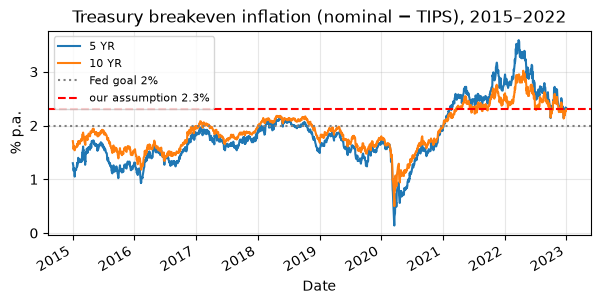

In [2]:
def treasury(kind):
    df = pd.concat([pd.read_csv(RAW / 'treasury' / f'{kind}_par_yield_{y}.csv') for y in range(2015, 2023)])
    df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
    df = df.set_index('Date').sort_index(); df.columns = [c.upper() for c in df.columns]
    return df
nom, real = treasury('nominal'), treasury('real')
be = (nom[['5 YR', '10 YR']] - real[['5 YR', '10 YR']]).dropna()
last = pd.DataFrame({'nominal %': nom.loc['2022-12-30', ['5 YR', '10 YR']], 'TIPS real %': real.loc['2022-12-30', ['5 YR', '10 YR']]})
last['breakeven %'] = last['nominal %'] - last['TIPS real %']
display(last)
fig, ax = plt.subplots(figsize=(7, 3))
be.plot(ax=ax); ax.axhline(2, color='grey', ls=':', label='Fed goal 2%'); ax.axhline(2.3, color='red', ls='--', label='our assumption 2.3%')
ax.set(ylabel='% p.a.', title='Treasury breakeven inflation (nominal − TIPS), 2015–2022'); ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()

**Output:** on 30 Dec 2022 the 5-year breakeven was 2.33% and the 10-year 2.30%. In March 2022 the 5-year breakeven reached 3.6%, which is why we use 3.5% as the stress case.

---

## 3. Size of the interest-rate scenarios (S3)

**What:** 12-month changes of month-end yields, 2015–2022. We use the 5th/95th percentiles of the change in the 5-year yield (parallel shifts) and of the change in the 10y − 2y slope (twists).

In [3]:
m = nom.resample('ME').last()
chg = pd.DataFrame({'5y yield': m['5 YR'].diff(12), '10y - 2y slope': (m['10 YR'] - m['2 YR']).diff(12)}).dropna() * 100
display(chg.describe(percentiles=[.05, .5, .95]).T[['count', 'mean', 'std', '5%', '50%', '95%']].round(0).rename(columns=lambda c: c + (' (bp)' if c != 'count' else '')))

,count,mean (bp),std (bp),5% (bp),50% (bp),95% (bp)
5y yield,84.0,22.0,117.0,-161.0,43.0,247.0
10y - 2y slope,84.0,-21.0,64.0,-139.0,-20.0,80.0


**Output:** the 95th percentile of the 12-month change in the 5-year yield is about +250 bp (driven by 2022), the 5th percentile about −160 bp. These are the shocks used in notebook 02, §3.5 and §5.6.

---

## 4. Equity risk premium and the equity stress size (S7)

**What:** from the saved Damodaran workbook we read (i) the implied ERP at the start of January 2023, (ii) the annual S&P 500 and 10-year T-bond returns 1928–2022, from which we compute the historical premium and look up the 2008 and 2022 returns.

**Values used:** ERP = 5.0% (lower end of the evidence); equity stress = −40% (≈ 2008).

In [4]:
xl = RAW / 'damodaran' / 'ERPJan23.xlsx'
calc = pd.read_excel(xl, sheet_name='Impl premium calculator', header=None)
row = calc[calc[0].astype(str).str.startswith('Implied Risk Premium in current level')].iloc[0]
implied_erp = float(row[2])
hist = pd.read_excel(xl, sheet_name='Historical ERP', usecols='A:D')
hist = hist[pd.to_numeric(hist['Year'], errors='coerce').between(1928, 2022)].astype(float).set_index('Year')
hist.columns = ['S&P 500', 'T-bill', 'T-bond']
out = {}
for a, b in [(1928, 2022), (1973, 2022), (2013, 2022)]:
    h = hist.loc[a:b]; n = len(h)
    out[f'{a}-{b}'] = {'arithmetic, stocks - T-bonds': (h['S&P 500'] - h['T-bond']).mean(),
                       'geometric, stocks - T-bonds': (1 + h['S&P 500']).prod() ** (1 / n) - (1 + h['T-bond']).prod() ** (1 / n)}
display(pd.DataFrame(out).style.format('{:.2%}'))
print(f'Implied ERP, start of January 2023: {implied_erp:.2%}')
print(f"S&P 500 total return: 2008 {hist.loc[2008, 'S&P 500']:.2%}, 2022 {hist.loc[2022, 'S&P 500']:.2%}")

,1928-2022,1973-2022,2013-2022
"arithmetic, stocks - T-bonds",6.64%,5.14%,13.08%
"geometric, stocks - T-bonds",5.06%,4.12%,12.32%


Implied ERP, start of January 2023: 5.94%
S&P 500 total return: 2008 -36.55%, 2022 -18.01%


**Output:** the long-run historical premium is 5.1% (geometric) to 6.6% (arithmetic); the implied premium is 5.94%. The last ten years (≈ 12%) are far above the long run and we do not use them. The S&P 500 lost 36.6% in 2008, so −40% is a little worse than the worst year in recent history.

*Note on dates:* the implied ERP uses the index level of 31 Dec 2022 but was published in early January 2023, so we use it only to check that our 5% is not too optimistic.

---

## 5. Risk-free rate data (S2)

In [5]:
with zipfile.ZipFile(RAW / 'french' / 'F-F_Research_Data_Factors_CSV.zip') as z:
    text = z.read(z.namelist()[0]).decode('latin-1').splitlines()
print('\n'.join(text[:3]))
rf = {l.split(',')[0]: float(l.split(',')[4]) for l in text if l[:6] in ('202212', '201601')}
print(f"\nRF (1-month T-bill, % per month): Jan 2016 {rf['201601']:.2f}, Dec 2022 {rf['202212']:.2f}")

This file was created using the 202608 CRSP database.
The 1-month TBill rate data until 202405 are from Ibbotson Associates. Starting from 202406, the 1-month TBill rate is from ICE BofA US 1-Month Treasury Bill Index. 
The annual TBill return is compounded from the monthly T-bill rates from January to December. 

RF (1-month T-bill, % per month): Jan 2016 0.01, Dec 2022 0.33


**Output:** the French files we downloaded were built from a recent CRSP vintage (see header). Values for 2016–2022 can differ very slightly from the version available on 31 Dec 2022; this is a known limitation that we cannot avoid with the current download. RF in Dec 2022 was 0.33% per month (≈ 4% p.a.).

---

## 6. Eligibility evidence: SEC filings before the cutoff (S8)

**What:** for each security, the latest periodic filing with a filing date on or before 31 Dec 2022, with a direct link to the filing on EDGAR.

In [6]:
SEC_CIK = {'MSA': 66570, 'KAI': 886346, 'GEF': 43920, 'IOSP': 1054905, 'FLO': 1128928, 'CALM': 16160,
           'IDA': 1057877, 'NWN': 1733998, 'CHE': 19584, 'NSIT': 932696, 'XMLV, RWL': 1378872, 'SPY': 884394}
rows = []
for t, cik in SEC_CIK.items():
    j = json.loads((RAW / 'sec' / f'CIK{cik:010d}.json').read_text())
    pages = [pd.DataFrame(j['filings']['recent'])] + [pd.DataFrame(json.loads((RAW / 'sec' / f['name']).read_text())) for f in j['filings'].get('files', [])]
    f = pd.concat(pages); f['filingDate'] = pd.to_datetime(f['filingDate'])
    forms = {'10-Q', '10-K'} if cik not in (1378872, 884394) else {'485BPOS', 'N-CSR', 'NPORT-P', 'N-30D'}
    f = f[(f['filingDate'] <= CUTOFF) & f['form'].isin(forms)].sort_values('filingDate').iloc[-1]
    acc = f['accessionNumber']
    link = f"https://www.sec.gov/Archives/edgar/data/{cik}/{acc.replace('-', '')}/{acc}-index.htm"
    rows.append(f"| {t} | {j['name']} | {cik} | {f['form']} | {f['filingDate']:%Y-%m-%d} | [{acc}]({link}) |")
display(Markdown('| Ticker | SEC entity | CIK | Latest form | Filed | Filing (EDGAR) |\n|:--|:--|--:|:--|:--|:--|\n' + '\n'.join(rows)))

| Ticker | SEC entity | CIK | Latest form | Filed | Filing (EDGAR) |
|:--|:--|--:|:--|:--|:--|
| MSA | MSA Safety Inc | 66570 | 10-Q | 2022-10-27 | [0000066570-22-000051](https://www.sec.gov/Archives/edgar/data/66570/000006657022000051/0000066570-22-000051-index.htm) |
| KAI | KADANT INC | 886346 | 10-Q | 2022-11-09 | [0000886346-22-000147](https://www.sec.gov/Archives/edgar/data/886346/000088634622000147/0000886346-22-000147-index.htm) |
| GEF | GREIF, INC | 43920 | 10-K | 2022-12-16 | [0000043920-22-000087](https://www.sec.gov/Archives/edgar/data/43920/000004392022000087/0000043920-22-000087-index.htm) |
| IOSP | INNOSPEC INC. | 1054905 | 10-Q | 2022-11-09 | [0001193125-22-280942](https://www.sec.gov/Archives/edgar/data/1054905/000119312522280942/0001193125-22-280942-index.htm) |
| FLO | FLOWERS FOODS INC | 1128928 | 10-Q | 2022-11-10 | [0000950170-22-024470](https://www.sec.gov/Archives/edgar/data/1128928/000095017022024470/0000950170-22-024470-index.htm) |
| CALM | CAL-MAINE FOODS INC | 16160 | 10-Q | 2022-12-28 | [0001562762-22-000497](https://www.sec.gov/Archives/edgar/data/16160/000156276222000497/0001562762-22-000497-index.htm) |
| IDA | IDACORP INC | 1057877 | 10-Q | 2022-11-03 | [0001057877-22-000072](https://www.sec.gov/Archives/edgar/data/1057877/000105787722000072/0001057877-22-000072-index.htm) |
| NWN | Northwest Natural Holding Co | 1733998 | 10-Q | 2022-11-08 | [0001733998-22-000048](https://www.sec.gov/Archives/edgar/data/1733998/000173399822000048/0001733998-22-000048-index.htm) |
| CHE | CHEMED CORP | 19584 | 10-Q | 2022-11-02 | [0001562762-22-000410](https://www.sec.gov/Archives/edgar/data/19584/000156276222000410/0001562762-22-000410-index.htm) |
| NSIT | INSIGHT ENTERPRISES INC | 932696 | 10-Q | 2022-11-03 | [0001628280-22-028025](https://www.sec.gov/Archives/edgar/data/932696/000162828022028025/0001628280-22-028025-index.htm) |
| XMLV, RWL | Invesco Exchange-Traded Fund Trust II | 1378872 | NPORT-P | 2022-12-30 | [0001752724-22-298091](https://www.sec.gov/Archives/edgar/data/1378872/000175272422298091/0001752724-22-298091-index.htm) |
| SPY | SPDR S&P 500 ETF TRUST | 884394 | NPORT-P | 2022-11-28 | [0001752724-22-271183](https://www.sec.gov/Archives/edgar/data/884394/000175272422271183/0001752724-22-271183-index.htm) |

**Output:** every issuer and both fund trusts filed with the SEC in the last quarter of 2022. XMLV and RWL are series of Invesco Exchange-Traded Fund Trust II (one CIK). Price and volume on 30 Dec 2022 (the second part of the eligibility check) are in notebook 02, Table T01/T02.

---

## 7. Assumptions we set ourselves (no outside data)

| Assumption | Value | Our reasoning |
|:--|--:|:--|
| Risk aversion $A$ | 4 | A foundation with fixed payments and loss-averse trustees; the course uses $A$ roughly 2–6. Tested 2–8. |
| Reading of "losses of about 15%" | stress ≤ 15%, VaR ≤ 10% (net of payments) | 15% = most they accept in a severe year; 10% for a normal 1-in-20 bad year. |
| Stock weight limits | 1%–8% of growth part | Every candidate stays in; no single firm can hurt much. |
| ETF weight limit | ≤ 35% each | Two ETFs can still be the core (≤ 70%) without one dominating. |
| Sector limit (stocks) | ≤ 15% | Two names per sector at most ≈ 8% + 7%. |
| Trading costs | 10 bp stocks, 3 bp ETFs, 0 for case bonds | Rough half spread + fees for liquid US securities; case bonds are bought at the quoted prices given in the case. |
| Cash reserve | USD 100,000 at 0% | Covers trading and rebalancing costs; 0% is conservative. |
| Rebalancing | each December, 3 pp drift band | Avoids frequent trading (L08 overconfidence) and fixes the rule in advance. |
| Coupon of 2023 | kept in cash at 0% to 2024 | Conservative; removes reinvestment risk for the 2024 payment. |

---

## 8. Optional: check that all links still work

Set `CHECK_LINKS = True` to test every link above (needs internet; the result does not affect the analysis).

In [7]:
CHECK_LINKS = False
LINKS = ['https://ranaroussi.github.io/yfinance/', 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html',
         'https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve&field_tdr_date_value=2022',
         'https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_real_yield_curve&field_tdr_date_value=2022',
         'https://fred.stlouisfed.org/series/T5YIE', 'https://fred.stlouisfed.org/series/T10YIE',
         'https://www.federalreserve.gov/monetarypolicy/files/FOMC_LongerRunGoals_202201.pdf',
         'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/implpr.html',
         'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/histretSP.html',
         'https://www.sec.gov/search-filings/edgar-application-programming-interfaces',
         'https://www.invesco.com/us/financial-products/etfs/product-detail?audienceType=Investor&ticker=XMLV',
         'https://www.invesco.com/us/financial-products/etfs/product-detail?audienceType=Investor&ticker=RWL',
         'https://www.ssga.com/us/en/intermediary/etfs/spdr-sp-500-etf-trust-spy', 'https://www.msci.com/our-solutions/indexes/gics']
if CHECK_LINKS:
    ua = {'User-Agent': 'BFIN-WS2026 Kappa group student project 106240420@student.vgu.edu.vn'}
    for u in LINKS:
        try: print(urllib.request.urlopen(urllib.request.Request(u, headers=ua), timeout=20).status, u)
        except Exception as e: print('ERROR', type(e).__name__, u)
else:
    print(f'{len(LINKS)} links listed; link check skipped (all returned HTTP 200 when we last checked on 22 Oct 2026).')

14 links listed; link check skipped (all returned HTTP 200 when we last checked on 22 Oct 2026).
